# Selección de variables (v2)

**Objetivo.** Elegir, entre las predictoras del preprocesamiento v2 y las variables derivadas del frío, un subconjunto manejable e informativo para pronosticar al cierre de **D** el consumo de frío de **D+1**.

**Entrada.** `data/processed/preprocesado_v2/historial_completo.csv`, generado por `src/preprocesamiento_v2.py` (ver `notebooks/preprocesamiento_v2.ipynb`). Se verifica su SHA-256 antes de usarlo.

**Métodos** (cada uno es una función independiente en `src/seleccion_v2.py`):

| Método | Qué mide | Cómo decide cuántas variables |
|---|---|---|
| Mutual Information | Dependencia (también no lineal) de cada variable con `y`, por separado | Curva k → MAE interno, regla de un error estándar |
| Ridge | \|coeficiente\| de una regresión Ridge con variables estandarizadas | Curva k → MAE interno, regla de un error estándar |
| Lasso | Coeficientes que la penalización L1 deja distintos de cero | El alpha de `LassoCV` |
| Forward | Agrega de a una la variable que más baja el MAE interno | Se detiene si la mejora es < 5 kW (máximo 25 variables) |

**Reglas contra la fuga de información:**

1. Todo método se ajusta **solo con Train**. Para elegir hiperparámetros y cantidad de variables se usa una **validación temporal interna** (`TimeSeriesSplit`, 5 bloques, con un día de hueco).
2. **Validation** se usa una sola vez: para comparar los subconjuntos finales entre sí y contra los baselines.
3. **Test no se lee** en esta notebook.
4. Las variables del frío (rezagos, medias móviles, desvío, diferencia) usan solo días ≤ D.

| Sección | Contenido |
|---|---|
| 1 | Datos y candidatas |
| 2 | Validación temporal interna |
| 3 | Mutual Information |
| 4 | Ridge |
| 5 | Lasso |
| 6 | Forward selection |
| 7 | Coincidencias entre métodos |
| 8 | Comparación en Validation |
| 9 | Exportación y comparación con el script |
| 10 | Conclusiones |

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

raiz = Path.cwd()
if raiz.name == "notebooks":
    raiz = raiz.parent
if str(raiz) not in sys.path:
    sys.path.insert(0, str(raiz))

import warnings
from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings("ignore", category=ConvergenceWarning)

from src import seleccion_v2 as sv2

pd.set_option("display.max_colwidth", 70)
pd.set_option("display.width", 200)

COLORES = {"mutual_information": "#2a78d6", "ridge": "#eb6834", "lasso": "#1baf7a",
           "forward": "#eda100", "consenso_2_metodos": "#e87ba4", "todas": "#52514e"}
plt.rcParams.update({
    "figure.figsize": (12, 4), "axes.grid": True, "grid.alpha": 0.25,
    "axes.spines.top": False, "axes.spines.right": False, "lines.linewidth": 1.4,
    "axes.titleweight": "bold", "axes.titlesize": 11,
})

def corto(nombre, largo=42):
    # Nombre legible: sin el sufijo de la hoja y recortado.
    base = nombre.rsplit("_", 1)[0] if "_" in nombre and not nombre.startswith(("frio_", "mes_", "dia_", "fin_")) else nombre
    return base if len(base) <= largo else base[:largo - 1] + "…"

cfg = sv2.ConfigSeleccion()
display(pd.Series(vars(cfg), name="valor").to_frame())

,valor
rezagos_frio,"(1, 2, 3, 4, 5, 6, 7, 14)"
ventanas_media_frio,"(2, 3, 5, 7, 10, 14, 21, 28)"
ventanas_mediana_frio,"(3, 7, 14)"
ventanas_desvio_frio,"(3, 7, 14)"
ventanas_extremos_frio,"(3, 7, 14)"
spans_media_exponencial_frio,"(3, 7, 14)"
diferencias_frio,"(1, 2, 3, 7)"
max_arrastre_dias,3
incluir_calendario,True
n_splits,5


## 1. Datos y candidatas

Las candidatas son:

* **Predictoras del preprocesamiento v2:** mediciones diarias limpias, imputadas y sin escalar, más los indicadores de imputación.
* **Variables del frío:** el frío de hoy ya está entre las predictoras. Se agregan varias familias, para que la selección decida qué memoria del consumo sirve:

  | Familia | Nombre | Ventanas o rezagos |
  |---|---|---|
  | Rezago | `frio_lag_k` (frío de D-k) | 1, 2, 3, 4, 5, 6, 7 y 14 días |
  | Media móvil | `frio_media_v` | 2, 3, 5, 7, 10, 14, 21 y 28 cierres |
  | Mediana móvil (robusta a un día atípico) | `frio_mediana_v` | 3, 7 y 14 cierres |
  | Desvío móvil (variabilidad reciente) | `frio_desvio_v` | 3, 7 y 14 cierres |
  | Mínimo y máximo de la ventana | `frio_min_v`, `frio_max_v` | 3, 7 y 14 cierres |
  | Media exponencial (pesa más lo reciente) | `frio_ewm_s` | span 3, 7 y 14 |
  | Diferencia (tendencia) | `frio_diff_k` (frío de D menos frío de D-k) | 1, 2, 3 y 7 días |

  La limpieza descartó 40 días calendario. Los rezagos y diferencias se miden en días calendario y, si falta un día, toman el último cierre anterior (hasta 3 días de arrastre). Las ventanas usan los últimos *v* cierres observados, así nunca quedan vacías.
* **Calendario:** `mes` (1 a 12, útil para los árboles), mes y día de la semana con codificación cíclica (seno y coseno, útil para los modelos lineales: diciembre y enero quedan cerca) e indicador de fin de semana.

In [2]:
historial = sv2.cargar_preprocesado()
candidatas = sv2.construir_candidatas(historial, cfg)
datos = sv2.particiones(historial, candidatas)
X_tr, y_tr, perdidas_tr = datos["train"]
X_val, y_val, perdidas_val = datos["validation"]

derivadas_frio = sv2.variables_frio(historial[sv2.COL_FRIO], cfg).columns
calendario = sv2.variables_calendario(historial.index[:1]).columns
origen = pd.Series("preprocesamiento v2", index=candidatas.columns)
origen[derivadas_frio] = "derivada del frío"
origen[calendario] = "calendario"
display(origen.value_counts().rename_axis("Origen").to_frame("Candidatas"))
familia_frio = pd.Series(derivadas_frio, index=derivadas_frio).str.extract(r"frio_([a-z]+)_")[0]
display(familia_frio.value_counts().rename_axis("Familia derivada del frío").to_frame("Variables"))

print(f"Train: {len(X_tr)} filas ({X_tr.index.min().date()} a {X_tr.index.max().date()}), "
      f"{perdidas_tr} sin historia suficiente al comienzo de la serie")
print(f"Validation: {len(X_val)} filas ({X_val.index.min().date()} a {X_val.index.max().date()}), "
      f"{perdidas_val} descartadas")

,Candidatas
Origen,
preprocesamiento v2,289
derivada del frío,35
calendario,6


,Variables
Familia derivada del frío,
lag,8
media,8
diff,4
mediana,3
desvio,3
min,3
max,3
ewm,3


Train: 786 filas (2020-07-15 a 2022-10-26), 12 sin historia suficiente al comienzo de la serie
Validation: 171 filas (2022-10-27 a 2023-04-29), 0 descartadas


In [3]:
# Control de causalidad de las variables del frío: recalcular con la historia cortada en
# una fecha da los mismos valores hasta esa fecha.
frio = historial[sv2.COL_FRIO]
corte = X_val.index.min()
completo = sv2.variables_frio(frio, cfg).loc[:corte]
parcial = sv2.variables_frio(frio.loc[:corte], cfg)
pd.testing.assert_frame_equal(completo, parcial)
print(f"Variables del frío causales: calcularlas con datos hasta {corte.date()} da el mismo resultado.")

Variables del frío causales: calcularlas con datos hasta 2022-10-27 da el mismo resultado.


## 2. Validación temporal interna

Dentro de Train, `TimeSeriesSplit` arma 5 bloques: cada uno se ajusta con el pasado y se evalúa con el período siguiente. El **hueco de un día** evita que el último `y` del ajuste (el frío del día siguiente) sea a la vez la predictora "frío de hoy" del primer día evaluado.

Con esta validación se elige el alpha de Ridge, que se usa en las curvas de los métodos de ranking y en forward.

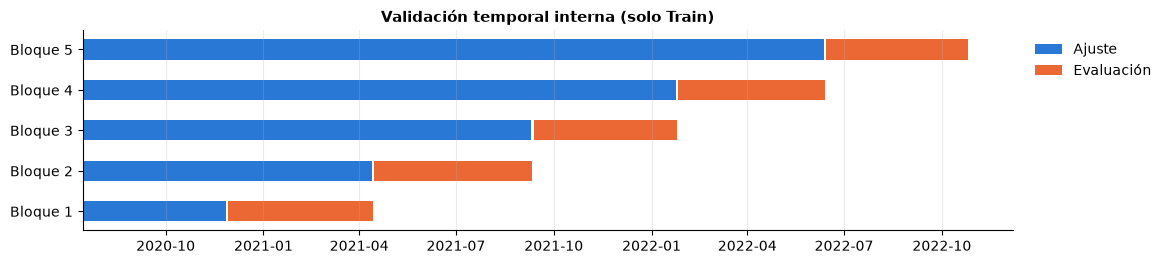

Alpha de Ridge elegido con todas las candidatas: 177.8279


In [4]:
cv = sv2.validacion_interna(cfg)
fig, ax = plt.subplots(figsize=(12, 2.6))
for i, (ajuste, evaluacion) in enumerate(cv.split(X_tr)):
    ax.barh(i, X_tr.index[ajuste[-1]] - X_tr.index[ajuste[0]], left=X_tr.index[ajuste[0]],
            color="#2a78d6", height=0.5, label="Ajuste" if i == 0 else None)
    ax.barh(i, X_tr.index[evaluacion[-1]] - X_tr.index[evaluacion[0]], left=X_tr.index[evaluacion[0]],
            color="#eb6834", height=0.5, label="Evaluación" if i == 0 else None)
ax.set_yticks(range(cfg.n_splits), [f"Bloque {i + 1}" for i in range(cfg.n_splits)])
ax.set_title("Validación temporal interna (solo Train)")
ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(1.01, 1))
ax.grid(axis="y", alpha=0)
plt.show()

alpha = sv2.elegir_alpha_ridge(X_tr, y_tr, cfg)
print(f"Alpha de Ridge elegido con todas las candidatas: {alpha}")

In [5]:
def graficar_curva(curva, titulo):
    fig, ax = plt.subplots(figsize=(9, 3.4))
    ax.errorbar(curva["k"], curva["mae_interno"], yerr=curva["error_estandar"], marker="o", ms=4,
                color="#2a78d6", ecolor="#86b6ef", capsize=3)
    elegido = curva[curva["elegido"]].iloc[0]
    minimo = curva.loc[curva["mae_interno"].idxmin()]
    ax.axhline(minimo["mae_interno"] + minimo["error_estandar"], color="#52514e", ls=":", lw=1,
               label="mínimo + 1 error estándar")
    ax.scatter([elegido["k"]], [elegido["mae_interno"]], s=90, color="#eb6834", zorder=5,
               label=f"elegido: k = {int(elegido['k'])}")
    ax.set_xscale("log")
    ax.set_xlabel("k (primeras variables del ranking)")
    ax.set_ylabel("MAE interno (kW)")
    ax.set_title(titulo)
    ax.legend(frameon=False)
    plt.show()

def graficar_ranking(tabla, columna, titulo, n=20, elegidas=()):
    top = tabla.head(n).iloc[::-1]
    colores = ["#2a78d6" if c in elegidas else "#b7d3f6" for c in top["columna"]]
    fig, ax = plt.subplots(figsize=(9, 0.28 * n + 1))
    ax.barh([corto(c) for c in top["columna"]], top[columna], color=colores, height=0.7)
    ax.set_title(titulo)
    ax.grid(axis="y", alpha=0)
    plt.show()

resultados = {}

## 3. Mutual Information

La información mutua mide cuánto reduce cada variable, **por separado**, la incertidumbre sobre `y`. Detecta relaciones no lineales, pero no tiene en cuenta la redundancia: dos variables casi iguales reciben puntajes parecidos.

Para decidir cuántas conservar se recorre el ranking y se mide el MAE interno de Ridge con las primeras *k*. Se elige el *k* más chico cuyo MAE no supera el mínimo más un error estándar (**regla de un error estándar**): ante resultados equivalentes, se prefiere el subconjunto más simple.

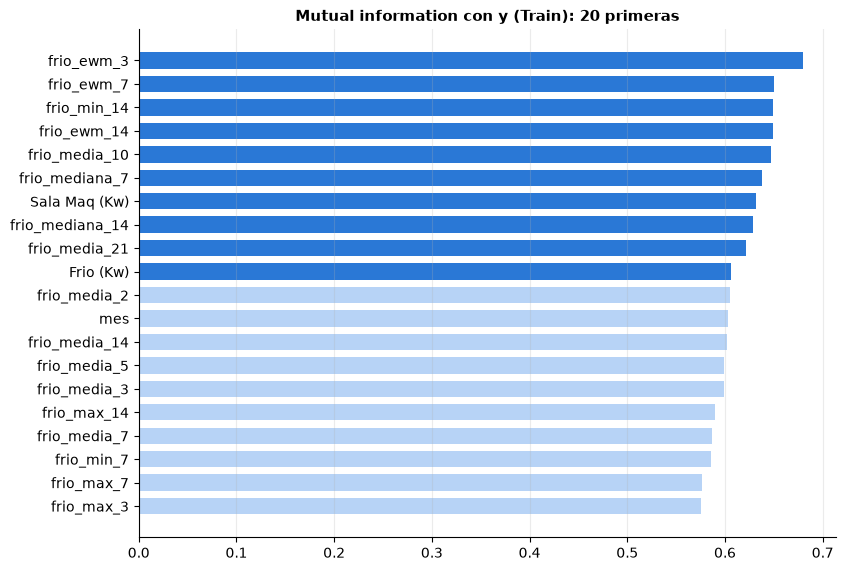

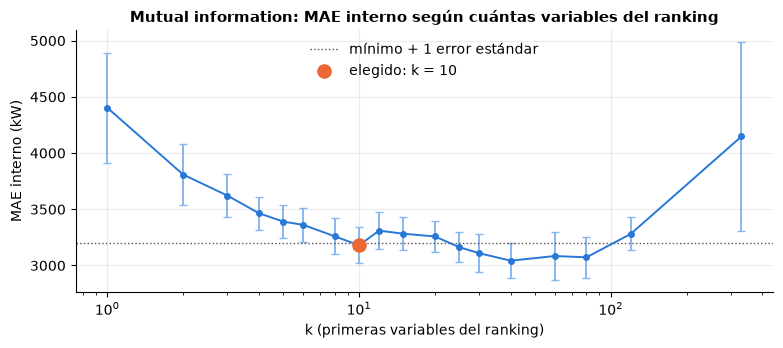

Elegidas: ['frio_ewm_3', 'frio_ewm_7', 'frio_min_14', 'frio_ewm_14', 'frio_media_10', 'frio_mediana_7', 'Sala Maq (Kw)', 'frio_mediana_14', 'frio_media_21', 'Frio (Kw)']


In [6]:
resultados["mutual_information"] = r = sv2.metodo_mutual_information(X_tr, y_tr, alpha, cfg)
graficar_ranking(r.tabla, "puntaje", "Mutual information con y (Train): 20 primeras", elegidas=r.columnas)
graficar_curva(r.curva, "Mutual information: MAE interno según cuántas variables del ranking")
print("Elegidas:", [corto(c) for c in r.columnas])

## 4. Ridge

Ridge ajusta todas las candidatas a la vez con penalización L2; con variables estandarizadas, el tamaño del coeficiente indica cuánto pesa cada una **dadas las demás**. Con variables muy correlacionadas, Ridge reparte el peso entre ellas, así que el ranking es menos estable que el de Lasso para elegir una sola de cada grupo. La cantidad se decide con la misma curva y la misma regla que en Mutual Information.

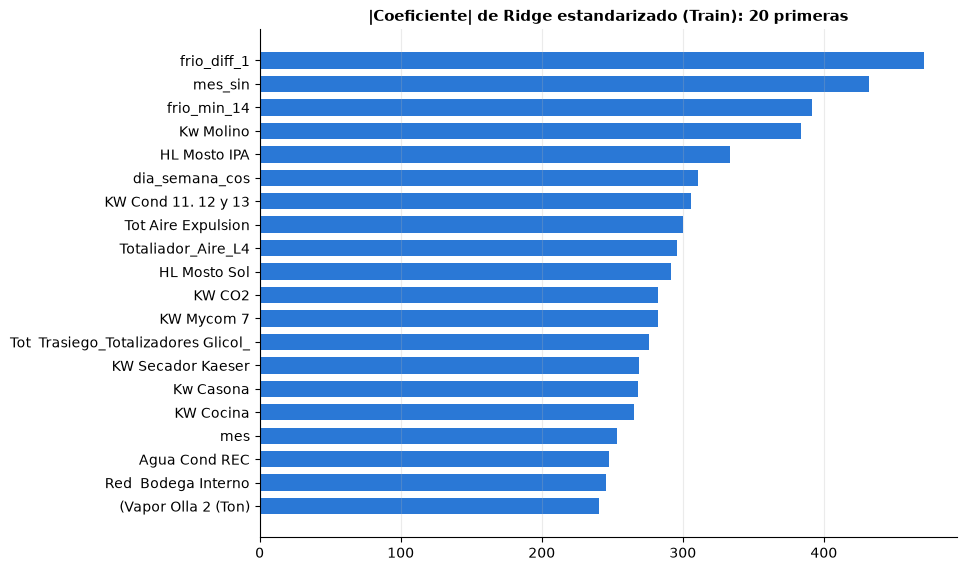

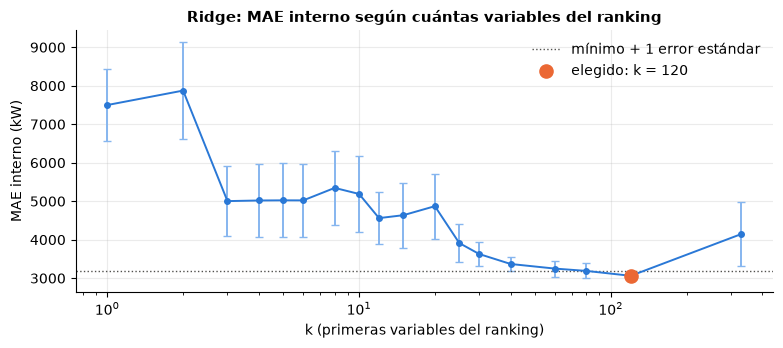

,columna,coeficiente
0,frio_diff_1,471.0
1,mes_sin,432.2
2,frio_min_14,391.7
3,Kw Molino,384.2
4,HL Mosto IPA,-333.7
...,...,...
115,Aire Elaboracion (m3),105.5
116,EE Caldera / Hl,-105.4
117,KW Mycom 5,105.1
118,Hl Cerveza Cocina,-103.8


In [7]:
resultados["ridge"] = r = sv2.metodo_ridge(X_tr, y_tr, alpha, cfg)
graficar_ranking(r.tabla, "puntaje", "|Coeficiente| de Ridge estandarizado (Train): 20 primeras", elegidas=r.columnas)
graficar_curva(r.curva, "Ridge: MAE interno según cuántas variables del ranking")
display(r.tabla.head(len(r.columnas))[["columna", "coeficiente"]].assign(columna=lambda d: d["columna"].map(corto)).round(1))

## 5. Lasso

Lasso (penalización L1) lleva coeficientes exactamente a cero: la selección es parte del ajuste. `LassoCV` elige el alpha con la misma validación temporal interna. Ante variables correlacionadas tiende a quedarse con una del grupo.

Alpha de Lasso: 198.33 | variables con coeficiente no nulo: 37


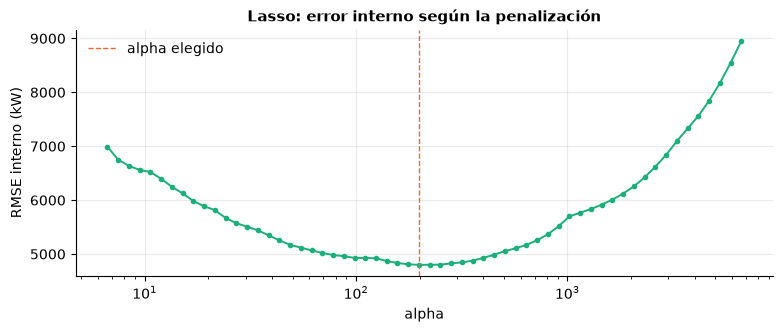

,columna,coeficiente
0,Frio (Kw),2187.6
1,frio_media_10,1644.4
2,Meta ET Planta,-744.3
3,mes_sin,548.4
4,mes_cos,-534.4
5,frio_min_14,487.1
6,KW Secador Kaeser,319.5
7,frio_diff_1,222.6
8,Red Paste L4,221.2
9,Agua Bodega / Hl,-218.4


In [8]:
resultados["lasso"] = r = sv2.metodo_lasso(X_tr, y_tr, alpha, cfg)
print(f"Alpha de Lasso: {r.detalle['alpha']:.2f} | variables con coeficiente no nulo: {len(r.columnas)}")
fig, ax = plt.subplots(figsize=(9, 3.2))
ax.plot(r.curva["alpha"], r.curva["rmse_interno"], color="#1baf7a", marker="o", ms=3)
ax.axvline(r.detalle["alpha"], color="#eb6834", ls="--", lw=1, label="alpha elegido")
ax.set_xscale("log")
ax.set_xlabel("alpha")
ax.set_ylabel("RMSE interno (kW)")
ax.set_title("Lasso: error interno según la penalización")
ax.legend(frameon=False)
plt.show()
display(r.tabla.head(len(r.columnas))[["columna", "coeficiente"]].assign(columna=lambda d: d["columna"].map(corto)).round(1))

## 6. Forward selection

Empieza sin variables y en cada paso agrega la que más baja el MAE interno de Ridge **junto con las ya elegidas**. A diferencia de los rankings, tiene en cuenta la redundancia: una variable que repite información de las anteriores no mejora el error y no entra. Se detiene cuando la mejora es menor a 5 kW.

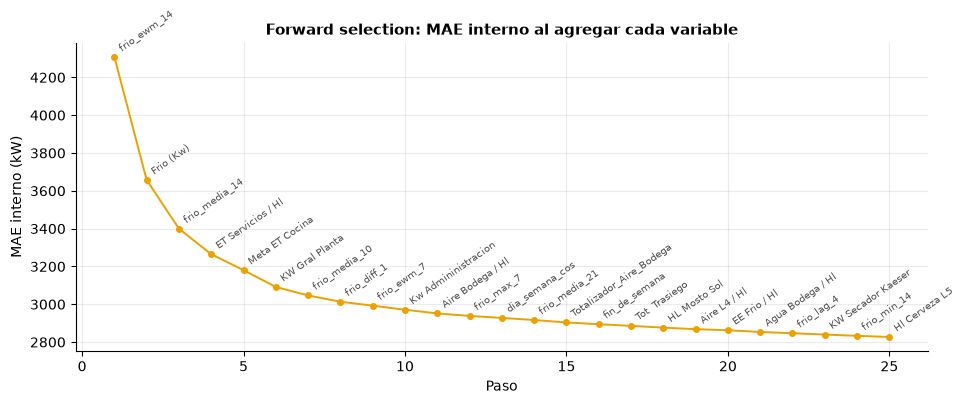

,paso,candidata,mae_interno,mejora_kw,agregada
0,1,frio_ewm_14,4308.0,inf,True
1,2,Frio (Kw),3657.5,650.6,True
2,3,frio_media_14,3399.7,257.8,True
3,4,ET Servicios / Hl,3264.8,134.9,True
4,5,Meta ET Cocina,3180.4,84.3,True
5,6,KW Gral Planta,3091.6,88.9,True
6,7,frio_media_10,3046.7,44.9,True
7,8,frio_diff_1,3013.4,33.3,True
8,9,frio_ewm_7,2992.6,20.8,True
9,10,Kw Admininistracion,2970.9,21.7,True


In [9]:
resultados["forward"] = r = sv2.metodo_forward(X_tr, y_tr, alpha, cfg)
recorrido = r.curva
agregadas = recorrido[recorrido["agregada"]]
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(agregadas["paso"], agregadas["mae_interno"], marker="o", ms=4, color="#eda100")
for _, fila in agregadas.iterrows():
    ax.annotate(corto(fila["candidata"], 26), (fila["paso"], fila["mae_interno"]), fontsize=7,
                rotation=35, xytext=(2, 4), textcoords="offset points", color="#52514e")
ax.set_xlabel("Paso")
ax.set_ylabel("MAE interno (kW)")
ax.set_title("Forward selection: MAE interno al agregar cada variable")
plt.show()
display(recorrido.assign(candidata=recorrido["candidata"].map(corto)).round(1))

## 7. Coincidencias entre métodos

Una variable que eligen varios métodos con criterios distintos es una candidata más robusta. Además del subconjunto de cada método se arma un **consenso**: las variables elegidas por al menos dos métodos.

In [10]:
subconjuntos = sv2.subconjuntos_a_comparar(resultados, list(X_tr.columns))
elegidas = sorted({c for r in resultados.values() for c in r.columnas})
votos = pd.DataFrame({m: [c in r.columnas for c in elegidas] for m, r in resultados.items()}, index=elegidas)
votos["n_metodos"] = votos.sum(axis=1)
votos = votos.sort_values("n_metodos", ascending=False, kind="stable")
votos.index = votos.index.map(corto)
display(votos[votos["n_metodos"] >= 2].replace({True: "✓", False: ""}))
print(f"Variables elegidas por algún método: {len(votos)} | por al menos dos: {(votos['n_metodos'] >= 2).sum()}")

# ¿Qué memoria del frío y qué calendario eligió cada método?
derivadas = [c for c in candidatas.columns if c in set(derivadas_frio) | set(calendario) or c == sv2.COL_FRIO]
tabla_derivadas = pd.DataFrame({m: [c in r.columnas for c in derivadas] for m, r in resultados.items()},
                               index=derivadas)
tabla_derivadas["n_metodos"] = tabla_derivadas.sum(axis=1)
tabla_derivadas = tabla_derivadas[tabla_derivadas["n_metodos"] > 0].sort_values("n_metodos", ascending=False, kind="stable")
tabla_derivadas.index = tabla_derivadas.index.map(corto)
print("\nFrío, derivadas del frío y calendario elegidas por al menos un método:")
display(tabla_derivadas.replace({True: "✓", False: ""}))

metodos = list(resultados)
jaccard = pd.DataFrame(index=metodos, columns=metodos, dtype=float)
for a in metodos:
    for b in metodos:
        A, B = set(resultados[a].columnas), set(resultados[b].columnas)
        jaccard.loc[a, b] = len(A & B) / len(A | B)
print("\nSolapamiento entre métodos (Jaccard):")
display(jaccard.round(2))

,mutual_information,ridge,lasso,forward,n_metodos
Frio (Kw),✓,✓,✓,✓,4
frio_media_10,✓,✓,✓,✓,4
frio_media_21,✓,✓,✓,✓,4
frio_min_14,✓,✓,✓,✓,4
Aire Bodega / Hl,,✓,✓,✓,3
ET Servicios / Hl,,✓,✓,✓,3
HL Mosto Sol,,✓,✓,✓,3
KW Secador Kaeser,,✓,✓,✓,3
Kw Admininistracion,,✓,✓,✓,3
Totalizador_Aire_Bodega,,✓,✓,✓,3


Variables elegidas por algún método: 125 | por al menos dos: 48

Frío, derivadas del frío y calendario elegidas por al menos un método:


,mutual_information,ridge,lasso,forward,n_metodos
Frio (Kw),✓,✓,✓,✓,4
frio_media_10,✓,✓,✓,✓,4
frio_media_21,✓,✓,✓,✓,4
frio_min_14,✓,✓,✓,✓,4
frio_media_14,,✓,✓,✓,3
frio_ewm_7,✓,✓,,✓,3
frio_ewm_14,✓,✓,,✓,3
frio_diff_1,,✓,✓,✓,3
dia_semana_cos,,✓,✓,✓,3
frio_lag_4,,✓,,✓,2



Solapamiento entre métodos (Jaccard):


,mutual_information,ridge,lasso,forward
mutual_information,1.00,0.07,0.09,0.21
ridge,0.07,1.00,0.29,0.18
lasso,0.09,0.29,1.00,0.29
forward,0.21,0.18,0.29,1.00


## 8. Comparación en Validation

Cada subconjunto se ajusta con **todo Train** y se evalúa una sola vez en Validation, con dos estimadores fijos para no favorecer a una familia de modelos: Ridge (con el alpha elegido en la sección 2) y un Random Forest con hiperparámetros fijos y semilla 42. Gana el **menor MAE promedio** entre los dos; ante un empate, el de menos columnas.

Los baselines obligatorios se calculan sobre las mismas filas de Validation: **persistencia** (mañana = hoy) y **media de 7 días** (promedio de D-6 a D).

In [11]:
comparacion = sv2.comparar_en_validation(subconjuntos, X_tr, y_tr, X_val, y_val, alpha, cfg)
baselines = sv2.baselines_validation(X_val, y_val)
display(pd.concat([comparacion, baselines], ignore_index=True).round(1))
ganador = comparacion.iloc[0]["subconjunto"]
mejor_baseline = baselines["mae_val_promedio"].min()
mejora = 1 - comparacion.iloc[0]["mae_val_promedio"] / mejor_baseline
print(f"Ganador: {ganador} ({len(subconjuntos[ganador])} variables) | "
      f"mejora sobre el mejor baseline: {mejora:.1%}")

,subconjunto,columnas,mae_val_ridge,mae_val_random_forest,mae_val_promedio
0,forward,25,2248.1,2234.7,2241.4
1,mutual_information,10,2197.1,2461.4,2329.2
2,consenso_2_metodos,48,2361.7,2313.7,2337.7
3,ridge,120,2326.9,2367.9,2347.4
4,lasso,37,2515.2,2317.6,2416.4
5,todas,330,2849.1,2340.6,2594.9
6,baseline_persistencia,0,NaN,NaN,2727.1
7,baseline_media_7,0,NaN,NaN,2398.3


Ganador: forward (25 variables) | mejora sobre el mejor baseline: 6.5%


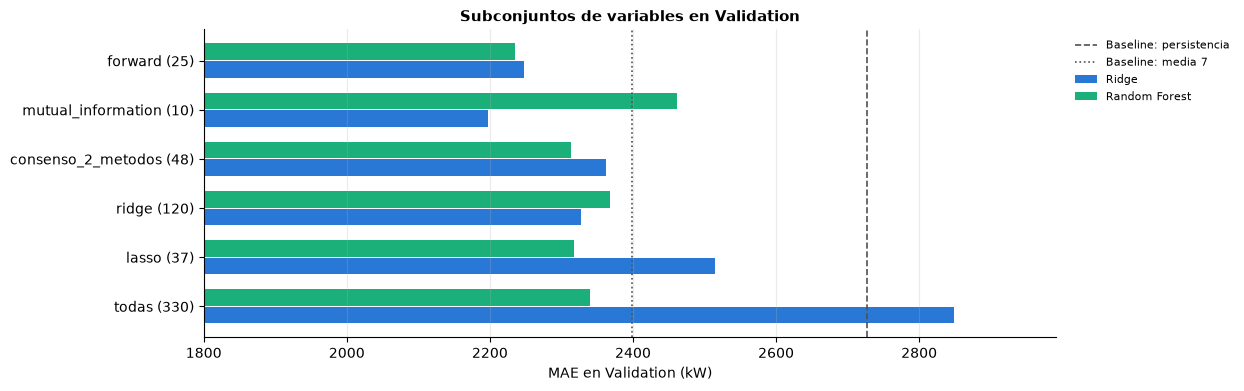

In [12]:
fig, ax = plt.subplots(figsize=(11, 4))
orden = comparacion.sort_values("mae_val_promedio", ascending=False)
pos = np.arange(len(orden))
ax.barh(pos - 0.18, orden["mae_val_ridge"], height=0.34, color="#2a78d6", label="Ridge")
ax.barh(pos + 0.18, orden["mae_val_random_forest"], height=0.34, color="#1baf7a", label="Random Forest")
for _, fila in baselines.iterrows():
    ax.axvline(fila["mae_val_promedio"], color="#52514e", ls="--" if "persistencia" in fila["subconjunto"] else ":",
               lw=1.2, label=fila["subconjunto"].replace("baseline_", "Baseline: ").replace("_", " "))
ax.set_yticks(pos, [f"{s} ({n})" for s, n in zip(orden["subconjunto"], orden["columnas"])])
ax.set_xlim(left=1800)
ax.set_xlabel("MAE en Validation (kW)")
ax.set_title("Subconjuntos de variables en Validation")
ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=8)
ax.grid(axis="y", alpha=0)
plt.show()

## 9. Exportación y comparación con el script

`sv2.ejecutar()` repite todo y guarda en `results/seleccion_v2/` los rankings, las curvas, los votos por variable, la comparación en Validation y `resumen.json`, que incluye la configuración, las fechas, el SHA-256 de la entrada y las columnas ganadoras. Comprobamos que llega al mismo resultado que esta notebook.

In [13]:
resultado_script = sv2.ejecutar(cfg)
assert resultado_script["ganador"] == ganador
assert resultado_script["subconjuntos"][ganador] == subconjuntos[ganador]
print("El script elige el mismo subconjunto que la notebook.")
print("\nVariables del subconjunto ganador:")
for i, c in enumerate(subconjuntos[ganador], 1):
    print(f"  {i:>2}. {c}")

SELECCIÓN DE VARIABLES V2
Candidatas: 330 | Train: 786 filas | Validation: 171 filas
Alpha de Ridge (validación temporal interna): 177.8279
  mutual_information  :  10 variables
  ridge               : 120 variables
  lasso               :  37 variables
  forward             :  25 variables
          subconjunto  columnas  mae_val_ridge  mae_val_random_forest  mae_val_promedio
              forward        25         2248.1                 2234.7            2241.4
   mutual_information        10         2197.1                 2461.4            2329.2
   consenso_2_metodos        48         2361.7                 2313.7            2337.7
                ridge       120         2326.9                 2367.9            2347.4
                lasso        37         2515.2                 2317.6            2416.4
                todas       330         2849.1                 2340.6            2594.9
baseline_persistencia         0            NaN                    NaN            2727.1
    

## 10. Conclusiones

In [14]:
tabla = pd.concat([comparacion, baselines], ignore_index=True)[["subconjunto", "columnas", "mae_val_promedio"]]
tabla["vs mejor baseline"] = (1 - tabla["mae_val_promedio"] / mejor_baseline).map("{:+.1%}".format)
display(tabla.round(1))

,subconjunto,columnas,mae_val_promedio,vs mejor baseline
0,forward,25,2241.4,+6.5%
1,mutual_information,10,2329.2,+2.9%
2,consenso_2_metodos,48,2337.7,+2.5%
3,ridge,120,2347.4,+2.1%
4,lasso,37,2416.4,-0.8%
5,todas,330,2594.9,-8.2%
6,baseline_persistencia,0,2727.1,-13.7%
7,baseline_media_7,0,2398.3,+0.0%


**Qué muestran los resultados:**

* **El frío reciente domina.** Los cuatro métodos eligen el frío de hoy, las medias de 10 y 21 cierres y el mínimo de 14; tres de cuatro eligen la media de 14, las medias exponenciales de 7 y 14, la diferencia diaria y el día de la semana (coseno). Coincide con lo visto en el preprocesamiento: casi toda la información sobre mañana ya está en la historia del frío.
* **Ventanas más que rezagos sueltos.** Entre las derivadas del frío, las ventanas (medias, mínimos, medias exponenciales) se eligen mucho más que los rezagos individuales: promediar varios días filtra el ruido diario. El `mes` como número lo elige solo el ranking de Ridge; los modelos lineales prefieren seno y coseno.
* **Producción y metas aportan poco, pero aparecen.** Forward incorpora una meta de energía térmica (`Meta ET Cocina`, estacional) y producción (`HL Mosto Sol`, `Hl Cerveza L5`), cada una con mejoras de pocas decenas de kW. Es lo esperable según las secciones 11 y 12 del preprocesamiento.
* **Hay variables que contienen al frío.** Mutual Information elige `Sala Maq (Kw)`; forward elige `KW Gral Planta` y `EE Frio / Hl` (frío de hoy dividido por los Hl de bodega). Todas incluyen el consumo de frío del mismo día. Usar el valor de **hoy** es legítimo (se conoce al cierre de D); usar el de mañana no lo sería. Ninguna variable de este pipeline usa datos posteriores a D.
* **Las diferencias entre subconjuntos son moderadas.** Forward (25 variables) gana con un MAE promedio de 2.241 kW, unos 90 kW por delante de Mutual Information y del consenso. Con Ridge el mejor es Mutual Information (10 variables, 2.197 kW); con Random Forest, forward (2.235 kW). Forward es el único que queda bien con los dos estimadores. Usar todas las variables es peor con Ridge, lo que confirma que la selección es necesaria para los modelos lineales.
* **La mejora sobre el baseline es modesta.** El ganador mejora a la media de 7 días (2.398 kW) en 6,5 %; el mejor resultado individual (Mutual Information con Ridge, 2.197 kW) la mejora en 8,4 %. Ninguno llega al 10 % que menciona la consigna. Parte de la explicación es el cambio de régimen de Validation (compresores Mycom, ver la sección 10 del preprocesamiento): las variables de equipos aprendidas en Train describen una operación que cambió.

**Decisiones para el modelado:**

1. Usar el subconjunto ganador como conjunto base, y el de Mutual Information como alternativa compacta para modelos lineales.
2. Antes de defender una diferencia entre subconjuntos, medir su variabilidad (por ejemplo, con bootstrap por bloques en Validation): con diferencias de alrededor de 100 kW, el ganador puede cambiar por ruido.
3. Probar en el modelado si quitar las variables de compresores individuales mejora la estabilidad frente al cambio de régimen.